## Proiect final Data Analyst - TechNova Solutions

## Etapa 2 – Analiză exploratorie în Python

### A. Încărcarea și curățarea tabelului evaluari


#### 1. Încărcarea datelor

Încarc cele trei fișiere CSV folosind pandas. Coloanele cu date din tabelul angajaților sunt interpretate ca date calendaristice. Afișez dimensiunile, informațiile despre coloane și primele rânduri pentru fiecare tabel.


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

angajati = pd.read_csv(
    "date/angajati_curat.csv",
    parse_dates=["data_nasterii", "data_angajarii", "data_plecarii"]
)

departamente = pd.read_csv("date/departamente.csv")
evaluari = pd.read_csv("date/evaluari.csv")

print("Tabelul angajati:")
print("Shape:", angajati.shape)
angajati.info()
display(angajati.head())

print("\nTabelul departamente:")
print("Shape:", departamente.shape)
departamente.info()
display(departamente.head())

print("\nTabelul evaluari:")
print("Shape:", evaluari.shape)
evaluari.info()
display(evaluari.head())


Tabelul angajati:
Shape: (480, 23)
<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_angajat          480 non-null    int64         
 1   nume                480 non-null    str           
 2   prenume             480 non-null    str           
 3   gen                 480 non-null    str           
 4   id_departament      480 non-null    int64         
 5   functie             480 non-null    str           
 6   nivel               480 non-null    str           
 7   oras                480 non-null    str           
 8   tip_contract        480 non-null    str           
 9   salariu_brut_lunar  480 non-null    int64         
 10  status              480 non-null    str           
 11  email               470 non-null    str           
 12  data_nasterii       480 non-null    datetime64[us]
 13  data_angajarii      480 no

,id_angajat,nume,prenume,gen,id_departament,functie,nivel,oras,tip_contract,salariu_brut_lunar,...,data_angajarii,data_plecarii,mediana_reper,mediana_salarii,motiv_plecare,nume_departament,varsta,vechime_ani,grupa_vechime,plecat
0,1081,Voicu,Bianca,F,60,Manager Suport Clienți,Manager,București,Full-time,8000,...,2018-01-20,2023-03-21,8000,8000,Relația cu managerul,Suport Clienți,45,5.2,> 5 ani,1
1,1038,Constantin,Simona,F,60,Manager Suport Clienți,Manager,Iași,Full-time,8000,...,2017-07-13,NaT,8000,8000,NaN,Suport Clienți,35,8.5,> 5 ani,0
2,1074,Nistor,Cristian,M,60,Operator Call Center,Mid,Timișoara,Full-time,4100,...,2024-07-24,NaT,4200,4200,NaN,Suport Clienți,27,1.4,1–3 ani,0
3,1333,Stan,Robert,M,60,Specialist Suport,Mid,Iași,Full-time,4300,...,2020-07-24,NaT,4200,4200,NaN,Suport Clienți,32,5.4,> 5 ani,0
4,1133,Constantin,Ana,F,60,Specialist Suport,Junior,Iași,Full-time,2750,...,2020-01-05,NaT,2825,2825,NaN,Suport Clienți,32,6.0,> 5 ani,0



Tabelul departamente:
Shape: (8, 4)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id_departament    8 non-null      int64
 1   nume_departament  8 non-null      str  
 2   oras_sediu        8 non-null      str  
 3   buget_anual_lei   8 non-null      int64
dtypes: int64(2), str(2)
memory usage: 388.0 bytes


,id_departament,nume_departament,oras_sediu,buget_anual_lei
0,10,IT,București,4200000
1,20,Vânzări,București,3100000
2,30,Marketing,Cluj-Napoca,1500000
3,40,Resurse Umane,București,900000
4,50,Financiar,Iași,1300000



Tabelul evaluari:
Shape: (1149, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1149 entries, 0 to 1148
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_evaluare              1149 non-null   int64  
 1   id_angajat               1149 non-null   int64  
 2   an_evaluare              1149 non-null   int64  
 3   scor_performanta         1119 non-null   float64
 4   satisfactie_angajat      1124 non-null   float64
 5   ore_suplimentare_lunare  1149 non-null   int64  
 6   ore_training_anual       1149 non-null   int64  
 7   zile_concediu_medical    1149 non-null   int64  
 8   procent_bonus            1149 non-null   float64
dtypes: float64(3), int64(6)
memory usage: 80.9 KB


,id_evaluare,id_angajat,an_evaluare,scor_performanta,satisfactie_angajat,ore_suplimentare_lunare,ore_training_anual,zile_concediu_medical,procent_bonus
0,1,1001,2023,3.0,6.0,2,35,5,4.9
1,4,1002,2023,4.0,6.0,0,36,4,7.0
2,7,1003,2023,3.0,NaN,9,40,9,4.8
3,9,1005,2023,3.0,4.0,16,2,8,5.5
4,12,1006,2023,5.0,7.0,0,15,5,12.5



#### 2. Verificarea calității datelor din evaluari

Verific duplicatele, valorile lipsă și valorile imposibile din coloanele scor_performanta, satisfactie_angajat și ore_suplimentare_lunare. Valorile trebuie să respecte intervalele definite în cerințele proiectului.


In [7]:

# Verificarea duplicatelor
print("Număr de rânduri duplicate:", evaluari.duplicated().sum())

# Verificarea valorilor lipsă
print("\nValori lipsă pe coloane:")
print(evaluari.isnull().sum())

# Verificarea valorilor imposibile
print("\nScor performanță în afara intervalului 1–5:")
print(((evaluari["scor_performanta"] < 1) |
       (evaluari["scor_performanta"] > 5)).sum())

print("\nSatisfacție în afara intervalului 1–10:")
print(((evaluari["satisfactie_angajat"] < 1) |
       (evaluari["satisfactie_angajat"] > 10)).sum())

print("\nOre suplimentare peste 100:")
print((evaluari["ore_suplimentare_lunare"] > 100).sum())


Număr de rânduri duplicate: 8

Valori lipsă pe coloane:
id_evaluare                 0
id_angajat                  0
an_evaluare                 0
scor_performanta           30
satisfactie_angajat        25
ore_suplimentare_lunare     0
ore_training_anual          0
zile_concediu_medical       0
procent_bonus               0
dtype: int64

Scor performanță în afara intervalului 1–5:
4

Satisfacție în afara intervalului 1–10:
3

Ore suplimentare peste 100:
3



#### 3. Curățarea duplicatelor și a valorilor imposibile

Elimin rândurile duplicate și transform valorile imposibile în valori lipsă (NaN). Aleg să elimin rândurile care conțin valori lipsă, deoarece completarea automată a scorurilor, satisfacției sau orelor suplimentare ar putea introduce informații care nu au fost înregistrate efectiv.


In [8]:

# Eliminarea duplicatelor
duplicate_initial = evaluari.duplicated().sum()
evaluari = evaluari.drop_duplicates().copy()

print("Duplicate eliminate:", duplicate_initial)

# Transformarea valorilor imposibile în NaN
evaluari.loc[
    ~evaluari["scor_performanta"].between(1, 5),
    "scor_performanta"
] = float("nan")

evaluari.loc[
    ~evaluari["satisfactie_angajat"].between(1, 10),
    "satisfactie_angajat"
] = float("nan")

evaluari.loc[
    evaluari["ore_suplimentare_lunare"] > 100,
    "ore_suplimentare_lunare"
] = float("nan")

# Eliminarea rândurilor care conțin cel puțin o valoare lipsă
randuri_inainte = len(evaluari)
evaluari = evaluari.dropna().copy()
randuri_eliminate_lipsa = randuri_inainte - len(evaluari)

print("Rânduri eliminate din cauza valorilor lipsă:",
      randuri_eliminate_lipsa)
print("Dimensiunea după curățare:", evaluari.shape)
print("\nValori lipsă rămase:")
print(evaluari.isnull().sum())


Duplicate eliminate: 8
Rânduri eliminate din cauza valorilor lipsă: 63
Dimensiunea după curățare: (1078, 9)

Valori lipsă rămase:
id_evaluare                0
id_angajat                 0
an_evaluare                0
scor_performanta           0
satisfactie_angajat        0
ore_suplimentare_lunare    0
ore_training_anual         0
zile_concediu_medical      0
procent_bonus              0
dtype: int64



#### 4. Verificarea cheilor străine

Verific dacă toate valorile id_angajat din tabelul evaluari există în tabelul angajati_curat. Elimin evaluările care nu au un angajat corespunzător și notez numărul rândurilor eliminate.


In [9]:

# Setul de ID-uri valide ale angajaților
id_angajati_valide = angajati["id_angajat"]

# Identificarea evaluărilor fără angajat corespunzător
evaluari_orfane = ~evaluari["id_angajat"].isin(id_angajati_valide)

numar_orfane = evaluari_orfane.sum()

print("Evaluări fără angajat corespunzător:", numar_orfane)

# Eliminarea evaluărilor orfane
evaluari = evaluari.loc[~evaluari_orfane].copy()

print("Dimensiunea finală după verificarea ID-urilor:",
      evaluari.shape)


Evaluări fără angajat corespunzător: 3
Dimensiunea finală după verificarea ID-urilor: (1075, 9)



#### 5. Salvarea datelor curățate

Salvez tabelul evaluari curățat în fișierul evaluari_curat.csv, fără a include indexul pandas. Acest fișier va putea fi utilizat în etapele următoare ale proiectului.


In [10]:

evaluari.to_csv("evaluari_curat.csv", index=False)

print("Fișierul evaluari_curat.csv a fost salvat.")
print("Număr final de evaluări:", len(evaluari))
display(evaluari.head())


Fișierul evaluari_curat.csv a fost salvat.
Număr final de evaluări: 1075


,id_evaluare,id_angajat,an_evaluare,scor_performanta,satisfactie_angajat,ore_suplimentare_lunare,ore_training_anual,zile_concediu_medical,procent_bonus
0,1,1001,2023,3.0,6.0,2.0,35,5,4.9
1,4,1002,2023,4.0,6.0,0.0,36,4,7.0
3,9,1005,2023,3.0,4.0,16.0,2,8,5.5
4,12,1006,2023,5.0,7.0,0.0,15,5,12.5
5,16,1008,2023,4.0,3.0,0.0,9,7,8.2


### B. Întrebări la care trebuie să răspunzi (cod + interpretare)


#### 1. Statistici descriptive pentru salariu, vârstă și vechime

Calculez media, mediana, minimul și maximul pentru salariul brut lunar, vârsta angajaților și vechimea în ani. Aceste statistici oferă o imagine generală asupra structurii personalului și a nivelului salarial.


In [24]:

coloane_statistici = [
    "salariu_brut_lunar",
    "varsta",
    "vechime_ani"
]

statistici = angajati[coloane_statistici].agg(
    ["mean", "median", "min", "max"]
).T

statistici.columns = ["Media", "Mediana", "Minim", "Maxim"]

display(statistici.round(2))


,Media,Mediana,Minim,Maxim
salariu_brut_lunar,6587.66,5950.0,2300.0,18200.0
varsta,37.39,37.0,21.0,56.0
vechime_ani,4.54,4.1,0.3,9.9



#### 2. Rata de plecare generală, pe departament și pe nivel

Calculez rata generală de plecare și ratele pe departament și nivel. Rata se obține ca media coloanei plecat, înmulțită cu 100 pentru a fi exprimată procentual.


In [12]:


# Rata generală de plecare
rata_generala = angajati["plecat"].mean() * 100

print(f"Rata generală de plecare: {rata_generala:.2f}%")

# Rata pe departament
rata_departament = (
    angajati.groupby("nume_departament")["plecat"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .reset_index(name="Rata plecare (%)")
)

print("\nRata de plecare pe departament:")
display(rata_departament)

# Rata pe nivel
rata_nivel = (
    angajati.groupby("nivel")["plecat"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .reset_index(name="Rata plecare (%)")
)

print("\nRata de plecare pe nivel:")
display(rata_nivel)



Rata generală de plecare: 23.96%

Rata de plecare pe departament:


,nume_departament,Rata plecare (%)
0,Vânzări,39.29
1,Suport Clienți,31.76
2,Juridic,25.00
3,Marketing,23.26
4,Financiar,19.44
5,Operațiuni,16.46
6,IT,16.07
7,Resurse Umane,12.00



Rata de plecare pe nivel:


,nivel,Rata plecare (%)
0,Junior,29.94
1,Senior,22.81
2,Mid,20.69
3,Manager,17.14



#### 3. Media evaluărilor pentru fiecare angajat

Calculez media evaluărilor fiecărui angajat pentru satisfacție, ore suplimentare, performanță, ore de training și procent bonus. Angajații fără evaluări vor avea valori lipsă pentru aceste indicatori.


In [26]:
coloane_evaluari = [
    "satisfactie_angajat",
    "ore_suplimentare_lunare",
    "scor_performanta",
    "ore_training_anual",
    "procent_bonus"
]

# Media evaluărilor pentru fiecare angajat
medii_angajati = (
    evaluari.groupby("id_angajat")[coloane_evaluari]
    .mean()
    .reset_index()
)

display(medii_angajati.head())


,id_angajat,satisfactie_angajat,ore_suplimentare_lunare,scor_performanta,ore_training_anual,procent_bonus
0,1001,5.333333,6.000000,3.666667,35.666667,6.466667
1,1002,6.333333,1.000000,4.000000,35.000000,6.933333
2,1005,4.666667,14.000000,2.666667,5.000000,4.266667
3,1006,6.333333,0.666667,4.000000,11.666667,8.700000
4,1007,7.000000,2.000000,5.000000,12.000000,14.700000




Unesc mediile evaluărilor cu tabelul angajaților folosind id_angajat și unirea de tip left. Astfel, păstrez toți angajații, inclusiv pe cei care nu au evaluări înregistrate.


In [14]:

angajati_cu_evaluari = angajati.merge(
    medii_angajati,
    on="id_angajat",
    how="left"
)

print("Dimensiunea tabelului combinat:",
      angajati_cu_evaluari.shape)

display(angajati_cu_evaluari.head())


Dimensiunea tabelului combinat: (480, 28)


,id_angajat,nume,prenume,gen,id_departament,functie,nivel,oras,tip_contract,salariu_brut_lunar,...,nume_departament,varsta,vechime_ani,grupa_vechime,plecat,satisfactie_angajat,ore_suplimentare_lunare,scor_performanta,ore_training_anual,procent_bonus
0,1081,Voicu,Bianca,F,60,Manager Suport Clienți,Manager,București,Full-time,8000,...,Suport Clienți,45,5.2,> 5 ani,1,6.000000,16.000000,3.000000,25.000000,3.600000
1,1038,Constantin,Simona,F,60,Manager Suport Clienți,Manager,Iași,Full-time,8000,...,Suport Clienți,35,8.5,> 5 ani,0,9.000000,9.666667,3.666667,22.333333,7.366667
2,1074,Nistor,Cristian,M,60,Operator Call Center,Mid,Timișoara,Full-time,4100,...,Suport Clienți,27,1.4,1–3 ani,0,6.000000,14.000000,3.000000,17.000000,4.700000
3,1333,Stan,Robert,M,60,Specialist Suport,Mid,Iași,Full-time,4300,...,Suport Clienți,32,5.4,> 5 ani,0,6.000000,8.666667,3.666667,37.333333,7.566667
4,1133,Constantin,Ana,F,60,Specialist Suport,Junior,Iași,Full-time,2750,...,Suport Clienți,32,6.0,> 5 ani,0,5.666667,10.333333,3.000000,21.666667,4.633333


Comparația dintre angajații activi și cei plecați

Compar mediile indicatorilor de evaluare, salariul brut lunar și vechimea în funcție de status. Valorile lipsă sunt ignorate automat la calcularea mediilor. Diferențele observate descriu grupurile și nu demonstrează automat o relație de cauzalitate.


In [15]:

coloane_comparatie = [
    "satisfactie_angajat",
    "ore_suplimentare_lunare",
    "scor_performanta",
    "ore_training_anual",
    "procent_bonus",
    "salariu_brut_lunar",
    "vechime_ani"
]

comparatie_status = (
    angajati_cu_evaluari.groupby("status")[coloane_comparatie]
    .mean()
    .round(2)
)

display(comparatie_status)


,satisfactie_angajat,ore_suplimentare_lunare,scor_performanta,ore_training_anual,procent_bonus,salariu_brut_lunar,vechime_ani
status,,,,,,,
Activ,6.57,7.21,3.55,23.44,6.79,6776.30,5.16
Plecat,6.00,10.38,3.56,25.85,6.89,5988.91,2.57



#### 4. Cele mai frecvente motive de plecare

Analizez motivele de plecare ale angajaților care au statusul „Plecat”. Folosesc value_counts() pentru a identifica cele mai frecvente trei motive de plecare.


In [16]:

motive_frecvente = (
    angajati.loc[
        angajati["status"] == "Plecat",
        "motiv_plecare"
    ]
    .value_counts()
    .head(3)
)

print("Cele mai frecvente 3 motive de plecare:")
display(motive_frecvente)


Cele mai frecvente 3 motive de plecare:


motiv_plecare
Salariu mai bun în altă parte         31
Echilibru viață-muncă                 24
Lipsa oportunităților de promovare    18
Name: count, dtype: int64


#### 5. Matricea de corelație

Construiesc matricea de corelație pentru salariu, vârstă, vechime, plecare, satisfacție, ore suplimentare, performanță, training și bonus. Identific cele mai puternice trei corelații după valoarea absolută, fără diagonala principală și fără perechile repetate. Corelația indică asocierea liniară, nu dovedește cauzalitatea.


In [17]:

import numpy as np

coloane_corelatie = [
    "salariu_brut_lunar",
    "varsta",
    "vechime_ani",
    "plecat",
    "satisfactie_angajat",
    "ore_suplimentare_lunare",
    "scor_performanta",
    "ore_training_anual",
    "procent_bonus"
]

# Selectarea coloanelor și calcularea matricei
date_corelatie = angajati_cu_evaluari[coloane_corelatie]
matrice_corelatie = date_corelatie.corr()

print("Matricea de corelație:")
display(matrice_corelatie.round(3))

# Păstrăm doar perechile unice, fără diagonala principală
masca = np.triu(
    np.ones(matrice_corelatie.shape, dtype=bool),
    k=1
)

corelatii_unice = (
    matrice_corelatie.where(masca)
    .stack()
    .reset_index()
)

corelatii_unice.columns = [
    "Variabila 1",
    "Variabila 2",
    "Corelatie"
]

# Clasificare după valoarea absolută
corelatii_unice["Valoare absoluta"] = (
    corelatii_unice["Corelatie"].abs()
)

top_3_corelatii = (
    corelatii_unice
    .sort_values("Valoare absoluta", ascending=False)
    .head(3)
)

print("\nCele mai puternice 3 corelații:")
display(top_3_corelatii.round(3))


Matricea de corelație:


,salariu_brut_lunar,varsta,vechime_ani,plecat,satisfactie_angajat,ore_suplimentare_lunare,scor_performanta,ore_training_anual,procent_bonus
salariu_brut_lunar,1.000,0.291,0.033,-0.113,0.168,-0.078,0.121,-0.127,0.105
varsta,0.291,1.000,0.032,-0.068,0.053,0.071,0.051,-0.048,0.050
vechime_ani,0.033,0.032,1.000,-0.392,0.081,-0.031,-0.052,-0.091,-0.045
plecat,-0.113,-0.068,-0.392,1.000,-0.121,0.205,0.004,0.085,0.017
satisfactie_angajat,0.168,0.053,0.081,-0.121,1.000,-0.094,-0.050,-0.004,-0.049
ore_suplimentare_lunare,-0.078,0.071,-0.031,0.205,-0.094,1.000,-0.012,0.053,-0.013
scor_performanta,0.121,0.051,-0.052,0.004,-0.050,-0.012,1.000,0.159,0.947
ore_training_anual,-0.127,-0.048,-0.091,0.085,-0.004,0.053,0.159,1.000,0.125
procent_bonus,0.105,0.050,-0.045,0.017,-0.049,-0.013,0.947,0.125,1.000



Cele mai puternice 3 corelații:


,Variabila 1,Variabila 2,Corelatie,Valoare absoluta
62,scor_performanta,procent_bonus,0.947,0.947
21,vechime_ani,plecat,-0.392,0.392
1,salariu_brut_lunar,varsta,0.291,0.291



#### 6. Numărul de angajări și plecări în perioada 2016–2025

Calculez numărul angajărilor în funcție de anul din data_angajarii și numărul plecărilor în funcție de anul din data_plecarii. Includ toți anii din intervalul 2016–2025, inclusiv anii fără angajări sau plecări.


In [18]:

# Intervalul de ani analizat
ani = range(2016, 2026)

# Extragem anul angajării și numărăm înregistrările
angajari_anuale = (
    angajati["data_angajarii"]
    .dt.year
    .value_counts()
    .reindex(ani, fill_value=0)
)

# Extragem anul plecării și numărăm înregistrările
plecari_anuale = (
    angajati["data_plecarii"]
    .dt.year
    .value_counts()
    .reindex(ani, fill_value=0)
)

# Tabelul final cu două coloane
evolutie_personal = pd.DataFrame({
    "angajari": angajari_anuale,
    "plecari": plecari_anuale
})

evolutie_personal.index.name = "an"

display(evolutie_personal)


,angajari,plecari
an,,
2016,45,0
2017,58,1
2018,51,7
2019,47,3
2020,51,7
2021,43,11
2022,52,15
2023,51,21
2024,47,11


### C. Grafice obligatorii


#### G1. Distribuția salariilor




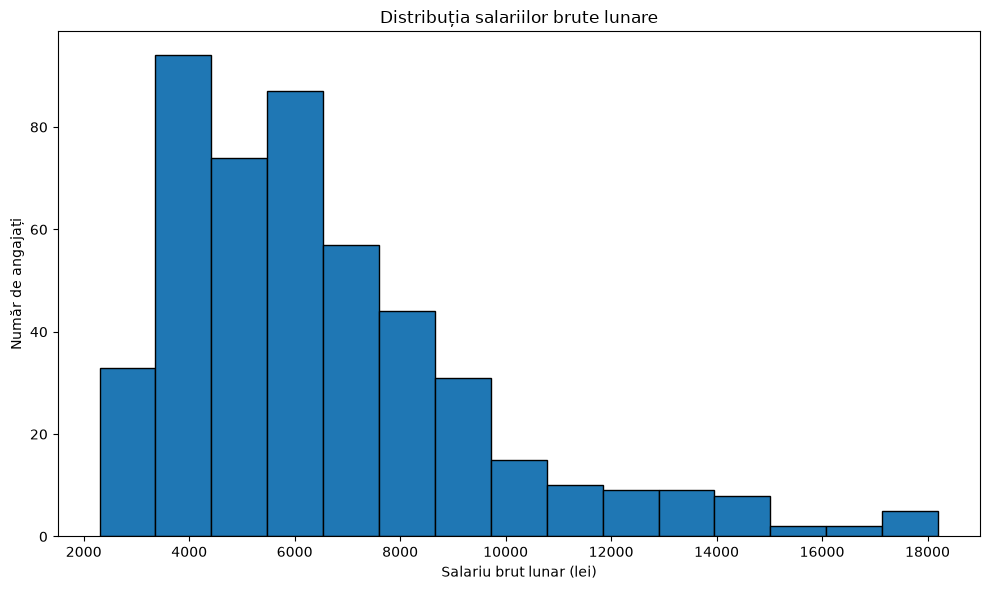

In [19]:

plt.figure(figsize=(10, 6))

salarii = angajati["salariu_brut_lunar"].dropna()

plt.hist(salarii, bins=15, edgecolor="black")

plt.title("Distribuția salariilor brute lunare")
plt.xlabel("Salariu brut lunar (lei)")
plt.ylabel("Număr de angajați")
plt.tight_layout()
plt.show()


#### G2. Salariul mediu pe nivel

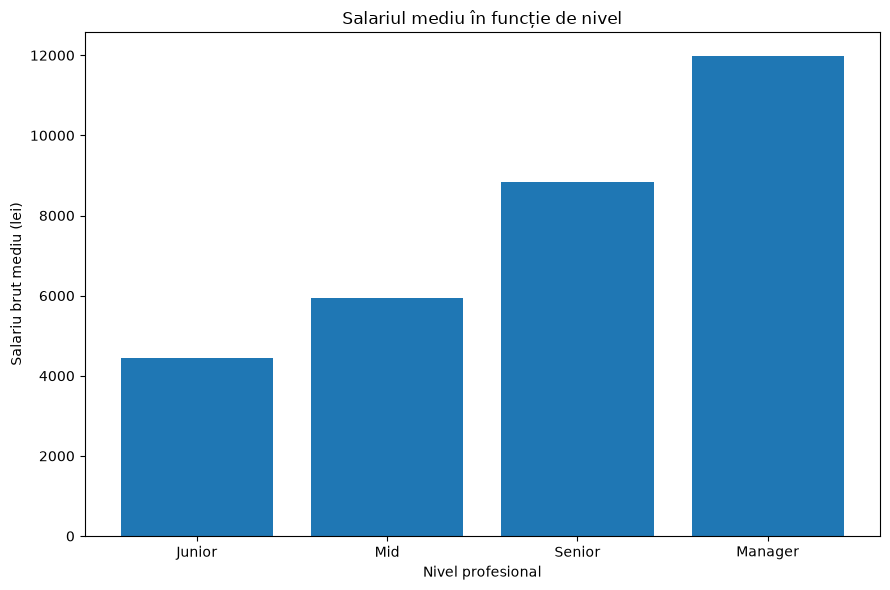

In [20]:

ordine_nivel = ["Junior", "Mid", "Senior", "Manager"]

salariu_mediu_nivel = (
    angajati.groupby("nivel")["salariu_brut_lunar"]
    .mean()
    .reindex(ordine_nivel)
)

plt.figure(figsize=(9, 6))

plt.bar(
    salariu_mediu_nivel.index,
    salariu_mediu_nivel.values
)

plt.title("Salariul mediu în funcție de nivel")
plt.xlabel("Nivel profesional")
plt.ylabel("Salariu brut mediu (lei)")
plt.tight_layout()
plt.show()


#### G3. Rata de plecare pe departament

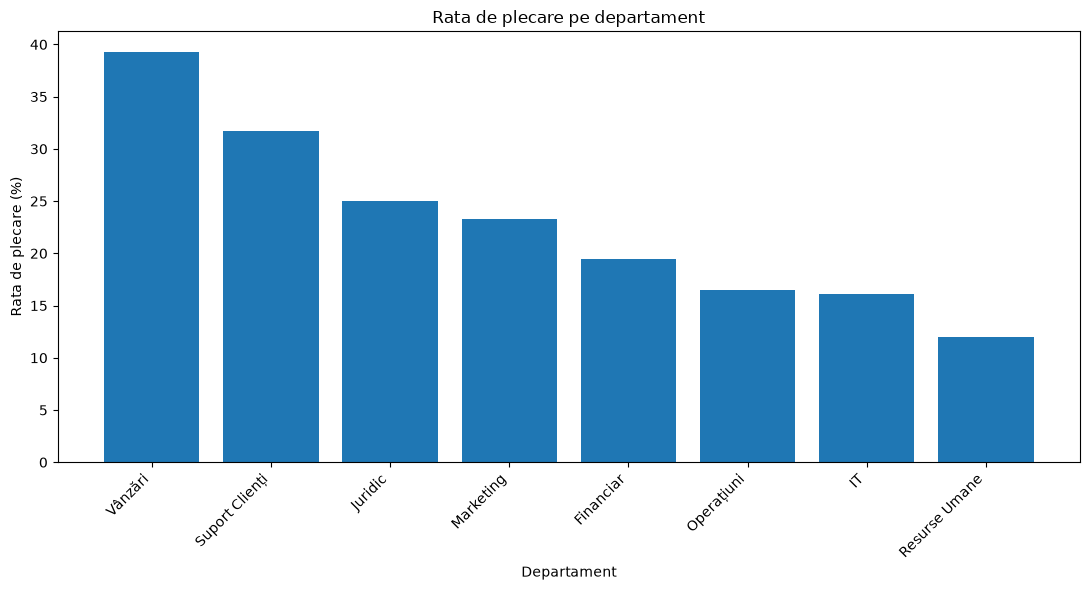

In [21]:

rata_departament_grafic = rata_departament.sort_values(
    "Rata plecare (%)",
    ascending=False
)

plt.figure(figsize=(11, 6))

plt.bar(
    rata_departament_grafic["nume_departament"],
    rata_departament_grafic["Rata plecare (%)"]
)

plt.title("Rata de plecare pe departament")
plt.xlabel("Departament")
plt.ylabel("Rata de plecare (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


#### G4. Proporția angajaților activi și plecați

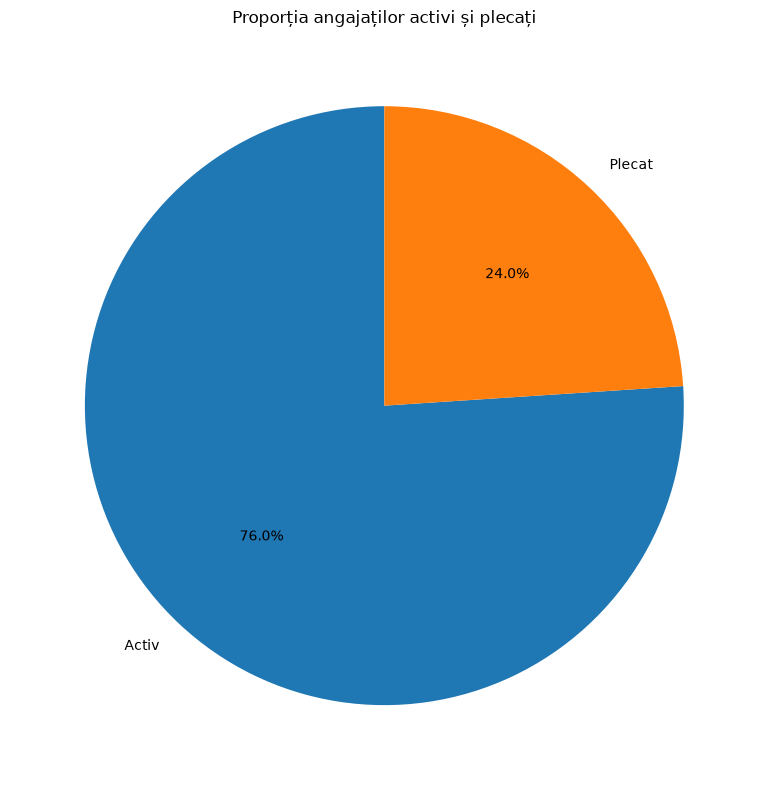

In [22]:

status_count = angajati["status"].value_counts()

# Etichete în limba română
etichete_status = {
    "Activ": "Activ",
    "Plecat": "Plecat"
}

labels = [
    etichete_status.get(status, status)
    for status in status_count.index
]

plt.figure(figsize=(8, 8))

plt.pie(
    status_count.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Proporția angajaților activi și plecați")
plt.tight_layout()
plt.show()



#### G5. Evoluția anuală a angajărilor și plecărilor




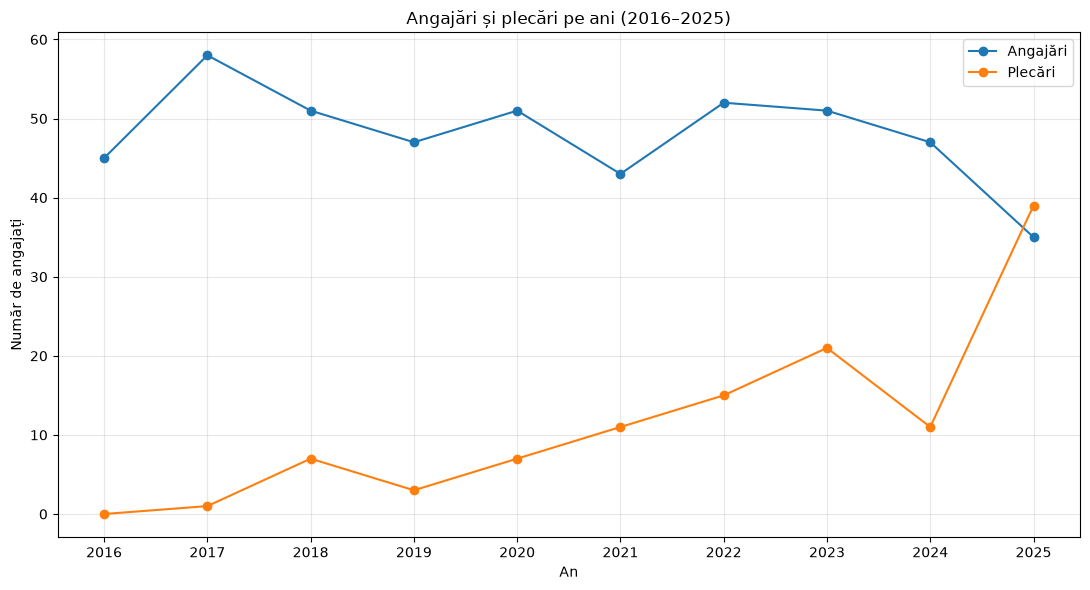

In [23]:

plt.figure(figsize=(11, 6))

plt.plot(
    evolutie_personal.index,
    evolutie_personal["angajari"],
    marker="o",
    label="Angajări"
)

plt.plot(
    evolutie_personal.index,
    evolutie_personal["plecari"],
    marker="o",
    label="Plecări"
)

plt.title("Angajări și plecări pe ani (2016–2025)")
plt.xlabel("An")
plt.ylabel("Număr de angajați")
plt.xticks(list(range(2016, 2026)))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
